# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

# complete

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3


In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [2]:
import numpy as np

# S = spam table
S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])

# Weights and bias
theta = np.array([0.3, 0.7])
bias = 0.5

# 1. Compute linear combination z
z = S @ theta + bias

print("z =", z)

# 2. Compute sigmoid probabilities
probabilities = 1 / (1 + np.exp(-z))

print("Probabilities =", probabilities)

# Identify predicted spam emails
predicted_spam = probabilities >= 0.5

print("Predicted spam =", predicted_spam)

z = [6.3 1.8 4.7 2.2]
Probabilities = [0.99816706 0.85814894 0.9909867  0.90024951]
Predicted spam = [ True  True  True  True]


In [ ]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities)
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [3]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [ ]:
# Auto graded cell (log)
# skip it

In [4]:
# Choose randomly 12 different indexes
# and set 12 integer values from [5, 11[ in failed_attempts

indexes = rng.choice(log.index, size=12, replace=False)

log.loc[indexes, "failed_attempts"] = rng.integers(5, 11, size=12)

In [ ]:
# Autograded cell (Failed attempts)
# Skip it

In [5]:
# Insert 10 missing values randomly

missing_indexes = rng.choice(log.index, size=10, replace=False)

log.loc[missing_indexes, "failed_attempts"] = np.nan

In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [6]:
# Count Russian logins with at least 5 failed attempts

ru_log_at_least_five_attempts = log[
    (log["country"] == "RU") &
    (log["failed_attempts"] >= 5)
].shape[0]

print(ru_log_at_least_five_attempts)

1


In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [7]:
# Calculate total failed attempts for each user
user_max_failed_attempts = (
    log.groupby("user")["failed_attempts"]
    .sum()
    .sort_values(ascending=False)
)

print(user_max_failed_attempts)
print("User with highest failed attempts:", user_max_failed_attempts.index[0])

user
ali       44.0
karim     42.0
nour      42.0
yacine    42.0
sara      36.0
Name: failed_attempts, dtype: float64
User with highest failed attempts: ali


In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [8]:
# Add long_session column
log['long_session'] = (log['duration_min'] > 30).astype(int)

In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

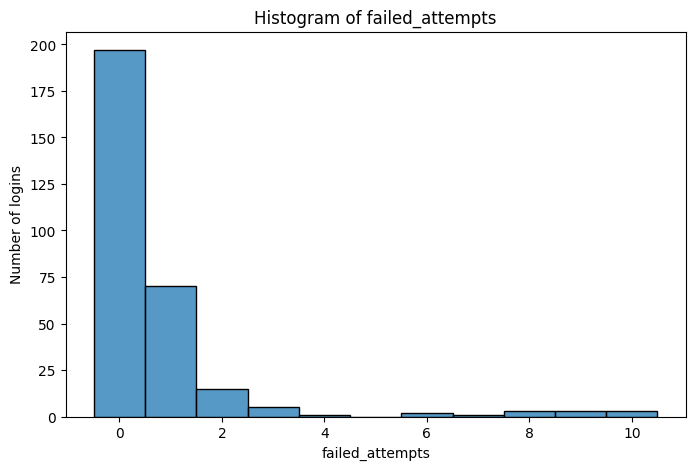

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(1)
n = 300

log = pd.DataFrame({
    "user": rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
    "hour": rng.integers(0, 24, n),
    "failed_attempts": rng.poisson(0.4, n),
    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[0.7, 0.15, 0.1, 0.05]),
    "duration_min": rng.gamma(2, 8, n).round(1)
})

idx_failed = rng.choice(n, size=12, replace=False)
log.loc[idx_failed, "failed_attempts"] = rng.integers(5, 11, size=12)
  # Draw the histogram of failed_attempts

plt.figure(figsize=(8, 5))

sns.histplot(
    data=log,
    x="failed_attempts",
    bins=range(0, 12),
    discrete=True
)

plt.xlabel("failed_attempts")
plt.ylabel("Number of logins")
plt.title("Histogram of failed_attempts")

plt.show()

In [ ]:
# Auto-graded cell - Skip it...

In [10]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

IndentationError: unexpected indent (1357432129.py, line 2)

In [11]:
# Write your code here
answer_q2 = "B: The distribution is highly skewed with zero-inflation and rare extreme bursts."

In [12]:
# 3. Draw a bar chart of the mean failed_attempts per night value.
import matplotlib.pyplot as plt

mean_per_night = df.groupby('night')['failed_attempts'].mean()

mean_per_night.plot(kind='bar', figsize=(10, 5))

plt.title('Mean Failed Attempts per Night')
plt.xlabel('Night')
plt.ylabel('Mean Failed Attempts')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [17]:
# Write your code here
X[:, 2]

NameError: name 'X' is not defined

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [16]:
df.isnull().sum()

NameError: name 'df' is not defined

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [15]:
sns.boxplot(data=df, x='country', y='failed_attempts')

NameError: name 'df' is not defined

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [14]:
We scale features to bring them to a similar range so that features with larger values do not dominate the model during training.

SyntaxError: invalid syntax (2438832995.py, line 1)

Commit the logins_clean.csv.(0.5 point)

In [13]:
logins_clean = log.dropna()
logins_clean.to_csv("logins_clean.csv", index=False)

In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [21]:
print(df.columns.tolist())

df["night"] = ((df["hour"] >= 22) | (df["hour"] < 6)).astype(int)

cols = ["hour", "failed_attempts", "duration_min", "night"]

X = df[cols].to_numpy()

scaler = StandardScaler()
X = scaler.fit_transform(X)

print(X.shape)


NameError: name 'df' is not defined

In [ ]:
import numpy as np
import pandas as pd
